In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

In [2]:
# Load data
demo = pd.read_sas("../data/DEMO_L.xpt", format="xport")
bmx  = pd.read_sas("../data/BMX_L.xpt", format="xport")
bpxo = pd.read_sas("../data/BPXO_L.xpt", format="xport")

# Data Flow
print("--- Data Flow ---")
print(f"Raw DEMO: {len(demo)}")
print(f"Raw BMX: {len(bmx)}")
print(f"Raw BPXO: {len(bpxo)}")

# Merge
merged1 = demo[['SEQN','RIAGENDR','RIDAGEYR','WTMEC2YR','SDMVPSU','SDMVSTRA']].merge(bmx[['SEQN','BMXBMI']], on='SEQN', how='inner')
merged2 = merged1.merge(bpxo[['SEQN','BPXOSY1','BPXOSY2','BPXOSY3']], on='SEQN', how='inner')
print(f"After merging: {len(merged2)}")

# Calculate Mean SBP
merged2['SBP_mean'] = merged2[['BPXOSY1','BPXOSY2','BPXOSY3']].mean(axis=1)

# Drop NaNs and Filter Adults
df = merged2.dropna(subset=['BMXBMI','SBP_mean'])
df = df[df['RIDAGEYR'] >= 18]
print(f"Final Analytical Population: {len(df)}")

--- Data Flow ---
Raw DEMO: 11933
Raw BMX: 8860
Raw BPXO: 7801
After merging: 7801
Final Analytical Population: 6061


In [3]:
# Descriptive Statistics
display(df[['BMXBMI','SBP_mean','RIDAGEYR']].describe().round(2))

# IQR
iqr_bmi = df['BMXBMI'].quantile(0.75) - df['BMXBMI'].quantile(0.25)
iqr_sbp = df['SBP_mean'].quantile(0.75) - df['SBP_mean'].quantile(0.25)
print(f"IQR for BMI: {iqr_bmi:.2f}")
print(f"IQR for SBP: {iqr_sbp:.2f}")

,BMXBMI,SBP_mean,RIDAGEYR
count,6061.00,6061.00,6061.00
mean,29.56,122.36,52.36
std,7.19,17.91,18.18
min,11.10,70.00,18.00
25%,24.50,110.33,37.00
50%,28.30,120.00,56.00
75%,33.30,132.00,67.00
max,68.90,215.00,80.00


IQR for BMI: 8.80
IQR for SBP: 21.67


In [4]:
# Raw vs Weighted Means
raw_bmi = df['BMXBMI'].mean()
weighted_bmi = (df['BMXBMI'] * df['WTMEC2YR']).sum() / df['WTMEC2YR'].sum()

raw_sbp = df['SBP_mean'].mean()
weighted_sbp = (df['SBP_mean'] * df['WTMEC2YR']).sum() / df['WTMEC2YR'].sum()

print("--- Raw vs Weighted ---")
print(f"BMI Raw: {raw_bmi:.2f} | BMI Weighted: {weighted_bmi:.2f}")
print(f"SBP Raw: {raw_sbp:.2f} | SBP Weighted: {weighted_sbp:.2f}")

--- Raw vs Weighted ---
BMI Raw: 29.56 | BMI Weighted: 29.47
SBP Raw: 122.36 | SBP Weighted: 120.77


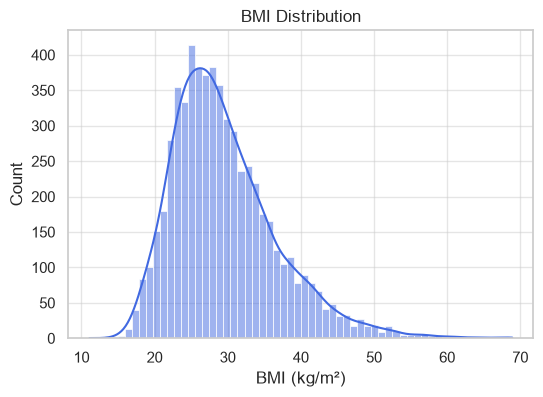

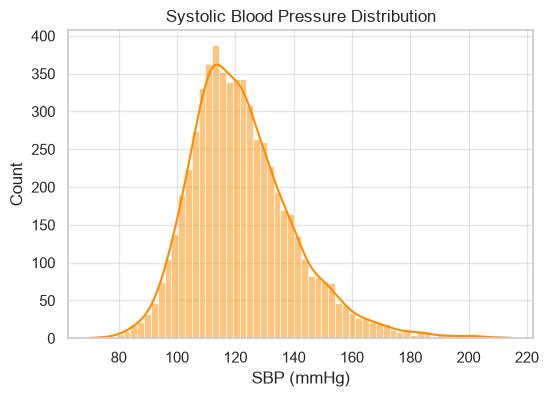

In [5]:
# Plot 1: BMI Histogram
plt.figure(figsize=(6, 4))
sns.histplot(df['BMXBMI'], kde=True, color='royalblue')
plt.title('BMI Distribution')
plt.xlabel('BMI (kg/m²)')
plt.show()

# Plot 2: SBP Histogram
plt.figure(figsize=(6, 4))
sns.histplot(df['SBP_mean'], kde=True, color='darkorange')
plt.title('Systolic Blood Pressure Distribution')
plt.xlabel('SBP (mmHg)')
plt.show()

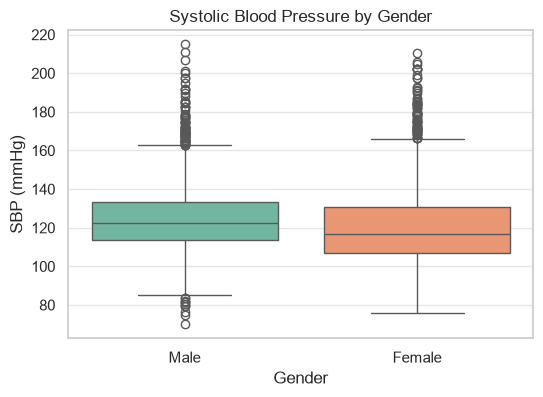

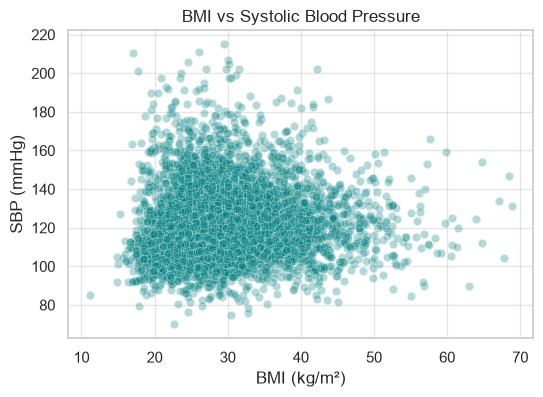

In [6]:
# Plot 3: Boxplot (Gender)
plt.figure(figsize=(6, 4))
sns.boxplot(x='RIAGENDR', y='SBP_mean', data=df, hue='RIAGENDR', palette='Set2', legend=False)
plt.xticks([0,1], ['Male', 'Female'])
plt.title('Systolic Blood Pressure by Gender')
plt.xlabel('Gender')
plt.ylabel('SBP (mmHg)')
plt.show()

# Plot 4: Scatter
plt.figure(figsize=(6, 4))
sns.scatterplot(x='BMXBMI', y='SBP_mean', data=df, alpha=0.3, color='teal')
plt.title('BMI vs Systolic Blood Pressure')
plt.xlabel('BMI (kg/m²)')
plt.ylabel('SBP (mmHg)')
plt.show()